# Problem 1 — Task 1: Data pipelines (5 marks)
Run all cells in order. Only standard-library, NumPy, PyTorch and Matplotlib code is used here.
Chosen settings under the instructor clarification: h=64; model/split seeds `(0, 1, 2)`.
Adding-data seeds remain fixed by the assignment, independently of model seeds.
AI assistance: Codex implemented and tested this permitted data-pipeline task; include this use in the final AI-use statement. Task 2 recurrent cells were subsequently AI-assisted after the user reported professor permission on 2026-11-09; disclose that assistance too.

In [1]:
from pathlib import Path
import random
import urllib.request
import zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path('.') if Path('problem1').is_dir() else Path('..')
DATA = ROOT / 'data'
FIGURES = ROOT / 'problem1' / 'figures'
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
SEEDS = (0, 1, 2)  # Chosen seeds, permitted by the instructor clarification.
CHANNELS = ('body_acc_x', 'body_acc_y', 'body_acc_z',
            'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
            'total_acc_x', 'total_acc_y', 'total_acc_z')
ACTIVITIES = ('walking', 'upstairs', 'downstairs', 'sitting', 'standing', 'laying')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [2]:
seed_everything(0)
a = (random.random(), np.random.rand(), torch.rand(1).item())
seed_everything(0)
assert a == (random.random(), np.random.rand(), torch.rand(1).item())
print('PASS: random, NumPy and PyTorch seed reproducibility')

PASS: random, NumPy and PyTorch seed reproducibility


In [3]:
def download_har(data_dir=DATA):
    """Download official archive, handling its optional nested ZIP."""
    destination = data_dir / 'har'
    found = [p for p in destination.rglob('UCI HAR Dataset') if (p / 'train' / 'y_train.txt').is_file()] if destination.exists() else []
    if found and (found[0] / 'test' / 'y_test.txt').exists():
        return found[0]
    archive = data_dir / 'har.zip'
    url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    if not archive.exists():
        temporary = archive.with_suffix('.download')
        urllib.request.urlretrieve(url, temporary)
        temporary.replace(archive)
    def extract(path, target):
        with zipfile.ZipFile(path) as z:
            # Reject archive members that escape the destination.
            for member in z.infolist():
                if not (target / member.filename).resolve().is_relative_to(target.resolve()):
                    raise ValueError('Unsafe ZIP member')
            z.extractall(target)
    extract(archive, destination)
    for nested in destination.rglob('*.zip'):
        extract(nested, nested.parent)
    found = [p for p in destination.rglob('UCI HAR Dataset') if (p / 'train' / 'y_train.txt').is_file()]
    if len(found) != 1:
        raise RuntimeError('Expected one UCI HAR Dataset directory')
    return found[0]

In [4]:
HAR_DIR = download_har()
assert (HAR_DIR / 'train' / 'Inertial Signals').is_dir()
assert (HAR_DIR / 'test' / 'subject_test.txt').is_file()
assert download_har() == HAR_DIR
print('PASS: official download, extraction and cached reuse')

PASS: official download, extraction and cached reuse


In [5]:
def load_har_split(root, split):
    if split not in ('train', 'test'):
        raise ValueError('split must be train or test')
    folder = root / split
    # Each channel is (windows, time); stack to (windows, time, channels).
    x = np.stack([np.loadtxt(folder / 'Inertial Signals' / f'{c}_{split}.txt',
                             dtype=np.float32) for c in CHANNELS], axis=-1)
    labels = np.loadtxt(folder / f'y_{split}.txt', dtype=np.int64)
    subjects = np.loadtxt(folder / f'subject_{split}.txt', dtype=np.int64)
    expected = 7352 if split == 'train' else 2947
    assert x.shape == (expected, 128, 9)
    assert labels.shape == subjects.shape == (expected,)
    assert np.array_equal(np.unique(labels), np.arange(1, 7))
    assert np.isfinite(x).all()
    return x, labels - 1, subjects  # CrossEntropyLoss requires labels 0..5.

In [6]:
x_train_raw, y_train_raw, subjects_train = load_har_split(HAR_DIR, 'train')
x_test_raw, y_test, subjects_test = load_har_split(HAR_DIR, 'test')
assert len(np.unique(subjects_train)) == 21
assert len(np.unique(subjects_test)) == 9
assert not set(subjects_train) & set(subjects_test)
for j, channel in enumerate(CHANNELS):
    expected = np.loadtxt(HAR_DIR / 'train' / 'Inertial Signals' / f'{channel}_train.txt', dtype=np.float32)
    np.testing.assert_array_equal(x_train_raw[:, :, j], expected)
assert set(y_train_raw) == set(range(6))
print('PASS: official shapes, channel order, labels, finite values and subject separation')
print('Train:', x_train_raw.shape, 'Test:', x_test_raw.shape)

PASS: official shapes, channel order, labels, finite values and subject separation
Train: (7352, 128, 9) Test: (2947, 128, 9)


In [7]:
def subject_split(subjects, seed):
    train_subjects = np.unique(subjects)
    held_out = np.random.default_rng(seed).choice(train_subjects, 4, replace=False)
    validation = np.isin(subjects, held_out)
    return np.flatnonzero(~validation), np.flatnonzero(validation), held_out

In [8]:
for seed in SEEDS:
    train_idx, val_idx, held_out = subject_split(subjects_train, seed)
    assert len(held_out) == 4
    assert not set(subjects_train[train_idx]) & set(subjects_train[val_idx])
    assert len(np.unique(subjects_train[train_idx])) == 17
    assert np.array_equal(np.sort(np.r_[train_idx, val_idx]), np.arange(7352))
    np.testing.assert_array_equal(held_out, subject_split(subjects_train, seed)[2])
print('PASS: three deterministic, exhaustive, subject-disjoint validation splits')

PASS: three deterministic, exhaustive, subject-disjoint validation splits


In [9]:
def fit_normalizer(training):
    # Pool windows and timesteps, preserving a broadcastable channel axis.
    mean = training.mean(axis=(0, 1), keepdims=True, dtype=np.float64)
    std = training.std(axis=(0, 1), keepdims=True, dtype=np.float64)
    if np.any(std <= 0):
        raise ValueError('Cannot normalize a constant channel')
    return mean, std

def normalize(x, mean, std):
    return ((x - mean) / std).astype(np.float32)

In [10]:
for seed in SEEDS:
    train_idx, val_idx, held_out = subject_split(subjects_train, seed)
    mean, std = fit_normalizer(x_train_raw[train_idx])
    train_x = normalize(x_train_raw[train_idx], mean, std)
    val_x = normalize(x_train_raw[val_idx], mean, std)
    test_x = normalize(x_test_raw, mean, std)
    np.testing.assert_allclose(train_x.mean(axis=(0, 1), dtype=np.float64), 0, atol=1e-6)
    np.testing.assert_allclose(train_x.std(axis=(0, 1), dtype=np.float64), 1, atol=1e-6)
    np.testing.assert_allclose(mean.ravel(), x_train_raw[train_idx].reshape(-1, 9).mean(axis=0, dtype=np.float64))
    # Validation/test use the frozen training transform, never their own statistics.
    np.testing.assert_array_equal(val_x, ((x_train_raw[val_idx] - mean) / std).astype(np.float32))
    np.testing.assert_array_equal(test_x, ((x_test_raw - mean) / std).astype(np.float32))
    assert all(np.isfinite(a).all() for a in (train_x, val_x, test_x))
    assert train_x.dtype == np.float32
    print(f'PASS seed {seed}: held-out subjects {sorted(held_out.tolist())}; windows {len(train_idx)}/{len(val_idx)}/{len(test_x)}; training-only normalization')
try:
    fit_normalizer(np.ones((2, 3, 9)))
except ValueError:
    pass
else:
    raise AssertionError('Constant channels must be rejected')

PASS seed 0: held-out subjects [8, 17, 21, 25]; windows 5886/1466/2947; training-only normalization


PASS seed 1: held-out subjects [15, 16, 25, 29]; windows 5905/1447/2947; training-only normalization


PASS seed 2: held-out subjects [5, 7, 11, 25]; windows 6017/1335/2947; training-only normalization


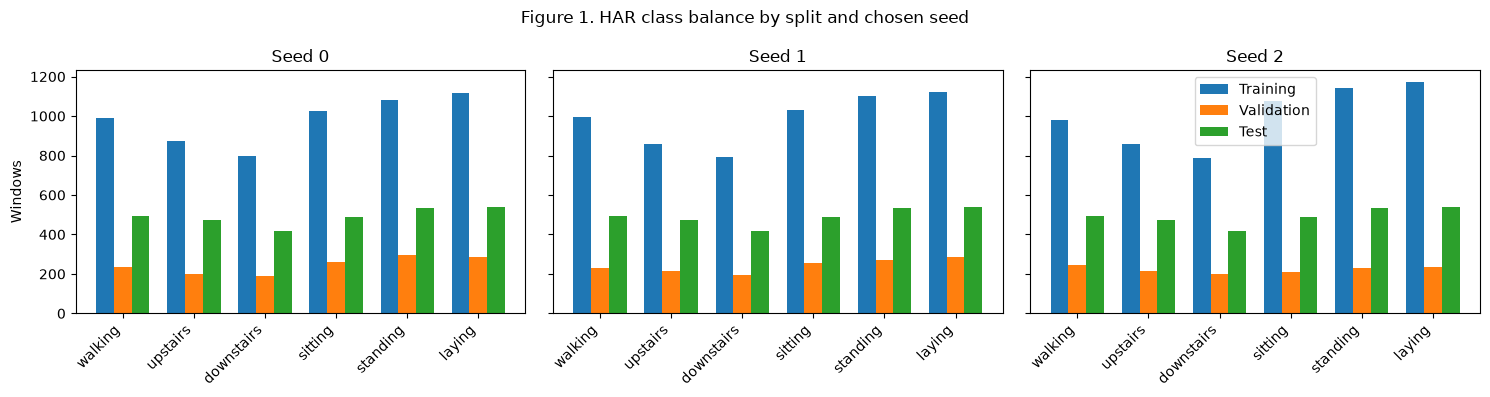

PASS: class-balance figure saved


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, seed in zip(axes, SEEDS):
    train_idx, val_idx, _ = subject_split(subjects_train, seed)
    for offset, labels, label in ((-0.25, y_train_raw[train_idx], 'Training'),
                                  (0, y_train_raw[val_idx], 'Validation'),
                                  (0.25, y_test, 'Test')):
        ax.bar(np.arange(6) + offset, np.bincount(labels, minlength=6), width=0.25, label=label)
    ax.set_xticks(np.arange(6), ACTIVITIES, rotation=45, ha='right')
    ax.set_title(f'Seed {seed}')
axes[0].set_ylabel('Windows')
axes[-1].legend()
fig.suptitle('Figure 1. HAR class balance by split and chosen seed')
fig.tight_layout()
figure_path = FIGURES / 'har_class_balance.png'
fig.savefig(figure_path, dpi=150, bbox_inches='tight')
plt.show()
assert figure_path.stat().st_size > 0
print('PASS: class-balance figure saved')

In [12]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

In [13]:
for T in (50, 100, 200, 400):
    for split, n, seed in (('train', 10000, 0), ('validation', 1000, 1), ('test', 1000, 2)):
        x, y = make_adding(n, T, seed)
        assert x.shape == (n, T, 2) and y.shape == (n,)
        assert x.dtype == y.dtype == np.float32
        markers = x[:, :, 1]
        assert np.isin(markers, [0, 1]).all()
        assert (markers.sum(axis=1) == 2).all()
        assert (markers[:, :T // 2].sum(axis=1) == 1).all()
        assert (markers[:, T // 2:].sum(axis=1) == 1).all()
        assert ((x[:, :, 0] >= 0) & (x[:, :, 0] < 1)).all()
        np.testing.assert_allclose(y, (x[:, :, 0] * markers).sum(axis=1), atol=1e-7, rtol=0)
        if split == 'test':
            print(f'T={T}: constant-1 test baseline MSE={np.mean((y - 1)**2):.6f}')
        del x, y
x1, y1 = make_adding(10, 51, 7)
x2, y2 = make_adding(10, 51, 7)
np.testing.assert_array_equal(x1, x2)
np.testing.assert_array_equal(y1, y2)
assert (x1[:, :25, 1].sum(axis=1) == 1).all()
assert (x1[:, 25:, 1].sum(axis=1) == 1).all()
print('PASS: all 12 required adding datasets, marker positions, targets, dtypes and reproducibility')

T=50: constant-1 test baseline MSE=0.175392
T=100: constant-1 test baseline MSE=0.169709
T=200: constant-1 test baseline MSE=0.167942
T=400: constant-1 test baseline MSE=0.152720
PASS: all 12 required adding datasets, marker positions, targets, dtypes and reproducibility


Task 1 ends here. No training experiments have been run, so `results.csv` contains only its required header. Final student-specific splits must be rerun when the variants table becomes available.

# Problem 1 — Task 2: Cells from scratch (10 marks)
**AI-assisted implementation:** On 2026-11-09 the user reported professor permission for full AI assistance. Constructors and forward equations below were implemented with AI assistance and must be disclosed. Verification results below determine completion. Do not call library recurrent layers, cell classes or fused recurrent operators from the custom cells.

Run All verifies each cell and records actual numerical errors. After implementing a cell, rerun its definition and adjacent verification cell. Any numerical or shape failure propagates as an assertion error. The strict final check is available after the three component checks.

## Parameter contract and equation references
Use the installed PyTorch `torch.nn.RNN.__doc__`, `torch.nn.LSTM.__doc__`, and `torch.nn.GRU.__doc__` mathematical definitions as references (reviewed for this environment). Reference layers appear only in verification code. Custom classes inherit `torch.nn.Module` and expose these **trainable parameters**, without child layers:

| Attribute | Shape | Meaning |
|---|---|---|
| `weight_ih` | `(g*h, d)` | Stacked input weights |
| `weight_hh` | `(g*h, h)` | Stacked recurrent weights |
| `bias_ih` | `(g*h,)` | Input biases |
| `bias_hh` | `(g*h,)` | Recurrent biases |

Here `g=1,4,3` for RNN/LSTM/GRU. Initialize parameters yourself with finite values, for example uniformly within ±1/√h; verification replaces them with reference weights. A cell takes one time step, not a full sequence. It requires an explicit state. Preserve input dtype/device and autograd.

### Parameter derivation (weights and biases only, no classifier)
Each gate has `h*d` input weights and `h*h` recurrent weights. With one bias its count is `h*d + h*h + h = h(d+h+1)`; multiply by gate count `g`. PyTorch stores **two** length-h bias vectors per gate, giving `g*h(d+h+2)`.

For d=9, h=64: input weights = 576, recurrent weights = 4096, one bias = 64. Thus one gate has 4736 parameters with one bias, or 4800 with two.

| Cell | g | Single-bias derivation | Two-bias PyTorch/custom contract |
|---|---:|---:|---:|
| RNN | 1 | 4736 | 4800 |
| LSTM | 4 | 18944 | 19200 |
| GRU | 3 | 14208 | 14400 |

The extra `g*h` accounts for the difference. RNN and LSTM biases can be summed for their forward equations. **GRU caveat:** the candidate recurrent bias is inside the reset multiplication in PyTorch; a generic single-bias GRU cannot simply absorb it into the input bias. Here the single-bias number is an architectural counting convention; the custom interface retains both biases for exact arbitrary-weight equivalence.


In [14]:
# Verification infrastructure only; no custom cell mathematics.
from torch import nn

CELL_RESULTS = {}  # Recreated on Run All; no stale success flags.
REFERENCE_CLASSES = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}
GATE_COUNTS = {'RNN': 1, 'LSTM': 4, 'GRU': 3}

def parameter_counts(d, h, gates):
    return gates * h * (d + h + 1), gates * h * (d + h + 2)

In [15]:
for kind, expected in {'RNN': (4736, 4800), 'LSTM': (18944, 19200), 'GRU': (14208, 14400)}.items():
    counts = parameter_counts(9, 64, GATE_COUNTS[kind])
    assert counts == expected
    reference = REFERENCE_CLASSES[kind](9, 64, batch_first=True)
    actual = sum(p.numel() for p in reference.parameters())
    assert actual == counts[1]
    print(f'{kind}: single-bias formula={counts[0]}, two-bias formula={counts[1]}, actual PyTorch={actual}; custom count checked in component verification below')

RNN: single-bias formula=4736, two-bias formula=4800, actual PyTorch=4800; custom count checked in component verification below
LSTM: single-bias formula=18944, two-bias formula=19200, actual PyTorch=19200; custom count checked in component verification below
GRU: single-bias formula=14208, two-bias formula=14400, actual PyTorch=14400; custom count checked in component verification below


In [16]:
def copy_reference_weights(custom, reference, kind, d, h):
    """Verification-only copy from a one-layer unidirectional reference."""
    g = GATE_COUNTS[kind]
    shapes = {'weight_ih': (g*h, d), 'weight_hh': (g*h, h),
              'bias_ih': (g*h,), 'bias_hh': (g*h,)}
    assert not list(custom.children()), 'Custom cells must use direct tensor parameters, no child layers'
    actual = dict(custom.named_parameters())
    assert set(actual) == set(shapes), f'Expected trainable parameters {tuple(shapes)}, got {tuple(actual)}'
    with torch.no_grad():
        for name, shape in shapes.items():
            assert actual[name].requires_grad
            assert tuple(actual[name].shape) == shape
            source = getattr(reference, name + '_l0')
            actual[name].copy_(source)
            assert torch.equal(actual[name], source), f'Weight copy failed: {name}'
    assert sum(p.numel() for p in custom.parameters()) == parameter_counts(d, h, g)[1]

In [17]:
# Test copying independently of any custom implementation.
probe = nn.Module()
ref_probe = nn.GRU(9, 64, batch_first=True)
for name, param in ref_probe.named_parameters():
    probe.register_parameter(name.removesuffix('_l0'), nn.Parameter(torch.zeros_like(param)))
copy_reference_weights(probe, ref_probe, 'GRU', 9, 64)
assert all(torch.equal(p, getattr(ref_probe, name + '_l0')) for name, p in probe.named_parameters())
print('PASS: verification weight-copy helper (not a custom-cell verification)')

PASS: verification weight-copy helper (not a custom-cell verification)


In [18]:
def assert_tensor_match(actual, expected, label):
    assert isinstance(actual, torch.Tensor), f'{label}: expected Tensor'
    assert actual.shape == expected.shape, f'{label}: {actual.shape} != {expected.shape}'
    assert actual.dtype == expected.dtype and actual.device == expected.device
    assert torch.isfinite(actual).all(), f'{label}: nonfinite output'
    error = (actual - expected).abs().max().item()
    assert error < 1e-5, f'{label}: max absolute error {error:.8g} must be < 1e-5'
    return error

In [19]:
assert assert_tensor_match(torch.zeros(2, 3), torch.zeros(2, 3), 'equal') == 0
for bad in (torch.zeros(3, 2), torch.ones(2, 3), torch.full((2, 3), float('nan'))):
    try:
        assert_tensor_match(bad, torch.zeros(2, 3), 'deliberate negative test')
    except AssertionError:
        pass
    else:
        raise AssertionError('Comparator accepted a deliberately invalid output')
print('PASS: comparison helper accepts equality and rejects shape/value/NaN errors')

PASS: comparison helper accepts equality and rejects shape/value/NaN errors


In [20]:
def verify_cell(cell_class, kind):
    """Strict verification: unfinished implementations raise NotImplementedError.

    Uses random nonzero states/biases, single and multiple timesteps, two seeds,
    float32/float64 and different batch/input/hidden sizes. Reference calls only.
    """
    worst = 0.0
    cases = 0
    with torch.random.fork_rng(devices=[]):
        for dtype in (torch.float32, torch.float64):
            for seed in (13, 29):
                for batch, steps, d, h in ((1, 1, 3, 5), (4, 7, 9, 64)):
                    torch.manual_seed(seed)
                    reference = REFERENCE_CLASSES[kind](d, h, batch_first=True).to(dtype=dtype)
                    custom = cell_class(d, h).to(dtype=dtype)
                    copy_reference_weights(custom, reference, kind, d, h)
                    x = torch.randn(batch, steps, d, dtype=dtype)
                    h0 = torch.randn(batch, h, dtype=dtype)
                    c0 = torch.randn(batch, h, dtype=dtype)
                    initial = (h0.unsqueeze(0), c0.unsqueeze(0)) if kind == 'LSTM' else h0.unsqueeze(0)
                    with torch.no_grad():
                        expected, final = reference(x, initial)
                        state = (h0.clone(), c0.clone()) if kind == 'LSTM' else h0.clone()
                        reference_state = initial
                        outputs = []
                        for t in range(steps):
                            state = custom(x[:, t, :], state)
                            _, reference_state = reference(x[:, t:t+1, :], reference_state)
                            if kind == 'LSTM':
                                assert isinstance(state, tuple) and len(state) == 2, 'LSTM must return (h_next, c_next)'
                                ht, ct = state
                                worst = max(worst, assert_tensor_match(ct, reference_state[1][0], 'cell state'))
                            else:
                                ht = state
                            worst = max(worst, assert_tensor_match(ht, expected[:, t, :], 'hidden state'))
                            outputs.append(ht)
                        worst = max(worst, assert_tensor_match(torch.stack(outputs, dim=1), expected, 'sequence'))
                        final_h = final[0][0] if kind == 'LSTM' else final[0]
                        worst = max(worst, assert_tensor_match(outputs[-1], final_h, 'final hidden'))
                    cases += 1
    return {'status': 'Completed', 'cases': cases, 'max_abs_diff': worst,
            'custom_params_d9_h64': sum(p.numel() for p in cell_class(9, 64).parameters())}


def report_cell_verification(cell_class, kind):
    # Clear stale success before attempting verification; catch only explicit TODOs.
    CELL_RESULTS[kind] = {'status': 'In Progress'}
    try:
        result = verify_cell(cell_class, kind)
    except NotImplementedError as exc:
        CELL_RESULTS[kind] = {'status': 'Blocked', 'reason': str(exc)}
        print(f'PENDING {kind}: student implementation required. {exc}')
        return
    CELL_RESULTS[kind] = result
    print(f'PASS {kind}: {result}')

In [21]:
class _UnfinishedProbe(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        raise NotImplementedError('harness negative-control placeholder')

try:
    verify_cell(_UnfinishedProbe, 'RNN')
except NotImplementedError:
    print('PASS: strict verifier rejects an unfinished implementation')
else:
    raise AssertionError('Unfinished cell was accepted')

PASS: strict verifier rejects an unfinished implementation


## MyRNNCell — AI-assisted implementation

The implementation uses the tanh Elman equation: $h_t=\tanh(x_tW_{ih}^{T}+b_{ih}+h_{t-1}W_{hh}^{T}+b_{hh})$. The two projected terms must both have shape `(batch,h)`. The implementation below translates this equation into tensor operations.

In [22]:
class MyRNNCell(nn.Module):
    """Tensor-only cell; AI-assisted under permission reported 2026-11-09."""
    def __init__(self, input_size, hidden_size):
        super().__init__()
        if input_size <= 0 or hidden_size <= 0:
            raise ValueError('input_size and hidden_size must be positive')
        self.input_size = input_size
        self.hidden_size = hidden_size
        # Packed rows: (1*h,d), (1*h,h); two biases match PyTorch.
        self.weight_ih = nn.Parameter(torch.empty(1 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(1 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(1 * hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(1 * hidden_size))
        bound = hidden_size ** -0.5
        for parameter in self.parameters():
            nn.init.uniform_(parameter, -bound, bound)

    def forward(self, x, h_prev):
        # x: (B,d), h_prev: (B,h); both projections yield (B,h).
        return torch.tanh(x @ self.weight_ih.T + self.bias_ih
                          + h_prev @ self.weight_hh.T + self.bias_hh)


In [23]:
report_cell_verification(MyRNNCell, 'RNN')

PASS RNN: {'status': 'Completed', 'cases': 8, 'max_abs_diff': 1.1920928955078125e-07, 'custom_params_d9_h64': 4800}


## MyLSTMCell — AI-assisted implementation

Use packed gate order **input, forget, candidate, output** (`i,f,g,o`). The three control gates use sigmoid and the candidate uses tanh. Combine the retained old cell state and gated candidate to obtain the new cell state; gate its tanh to obtain the new hidden state. See the equations in `torch.nn.LSTM.__doc__`. Return `(h_next, c_next)`, each `(batch,h)`; do not swap their order.

In [24]:
class MyLSTMCell(nn.Module):
    """Tensor-only cell; AI-assisted under permission reported 2026-11-09."""
    def __init__(self, input_size, hidden_size):
        super().__init__()
        if input_size <= 0 or hidden_size <= 0:
            raise ValueError('input_size and hidden_size must be positive')
        self.input_size = input_size
        self.hidden_size = hidden_size
        # Packed rows: (4*h,d), (4*h,h); two biases match PyTorch.
        self.weight_ih = nn.Parameter(torch.empty(4 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(4 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(4 * hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(4 * hidden_size))
        bound = hidden_size ** -0.5
        for parameter in self.parameters():
            nn.init.uniform_(parameter, -bound, bound)

    def forward(self, x, state):
        # x: (B,d); h_prev/c_prev: (B,h); packed gates: (B,4h).
        h_prev, c_prev = state
        gates = (x @ self.weight_ih.T + self.bias_ih
                 + h_prev @ self.weight_hh.T + self.bias_hh)
        i, f, g, o = gates.chunk(4, dim=-1)  # PyTorch order: i,f,g,o.
        c_next = torch.sigmoid(f) * c_prev + torch.sigmoid(i) * torch.tanh(g)
        h_next = torch.sigmoid(o) * torch.tanh(c_next)
        return h_next, c_next  # Each state is (B,h).


In [25]:
report_cell_verification(MyLSTMCell, 'LSTM')

PASS LSTM: {'status': 'Completed', 'cases': 8, 'max_abs_diff': 2.384185791015625e-07, 'custom_params_d9_h64': 19200}


## MyGRUCell — AI-assisted implementation

Use packed gate order **reset, update, new** (`r,z,n`). PyTorch applies reset **after** the recurrent candidate projection and includes the recurrent candidate bias inside that reset multiplication. It does not project a reset-multiplied hidden state. The update gate weights the old hidden state; its complement weights the candidate. See `torch.nn.GRU.__doc__`. Keep input and recurrent candidate biases separate.

In [26]:
class MyGRUCell(nn.Module):
    """Tensor-only cell; AI-assisted under permission reported 2026-11-09."""
    def __init__(self, input_size, hidden_size):
        super().__init__()
        if input_size <= 0 or hidden_size <= 0:
            raise ValueError('input_size and hidden_size must be positive')
        self.input_size = input_size
        self.hidden_size = hidden_size
        # Packed rows: (3*h,d), (3*h,h); two biases match PyTorch.
        self.weight_ih = nn.Parameter(torch.empty(3 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(3 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(3 * hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(3 * hidden_size))
        bound = hidden_size ** -0.5
        for parameter in self.parameters():
            nn.init.uniform_(parameter, -bound, bound)

    def forward(self, x, h_prev):
        # x: (B,d), h_prev: (B,h); packed projections: (B,3h).
        ir, iz, inn = (x @ self.weight_ih.T + self.bias_ih).chunk(3, dim=-1)
        hr, hz, hn = (h_prev @ self.weight_hh.T + self.bias_hh).chunk(3, dim=-1)
        reset = torch.sigmoid(ir + hr)
        update = torch.sigmoid(iz + hz)
        # PyTorch resets the projected recurrent candidate INCLUDING its bias.
        candidate = torch.tanh(inn + reset * hn)
        return (1 - update) * candidate + update * h_prev


In [27]:
report_cell_verification(MyGRUCell, 'GRU')

PASS GRU: {'status': 'Completed', 'cases': 8, 'max_abs_diff': 2.384185791015625e-07, 'custom_params_d9_h64': 14400}


## Task 2 completion check
The normal summary allows Task 1 to keep running if a future implementation is unfinished. **A successful notebook run is not Task 2 completion.** Once all cells are implemented, run `require_task2_complete()` explicitly; it re-verifies every class, rather than trusting stored results. The progress tracker must then be updated after reviewing the implementation and the saved evidence.

In [28]:
def require_task2_complete():
    verified = {}
    for kind, cls in (('RNN', MyRNNCell), ('LSTM', MyLSTMCell), ('GRU', MyGRUCell)):
        verified[kind] = verify_cell(cls, kind)
        assert verified[kind]['custom_params_d9_h64'] == parameter_counts(9, 64, GATE_COUNTS[kind])[1]
    return verified

print('Task 2 verification summary:', CELL_RESULTS)
if all(CELL_RESULTS.get(k, {}).get('status') == 'Completed' for k in GATE_COUNTS):
    print('All three verification suites passed; AI-use disclosure and documentation review required.')
else:
    print('TASK 2 INCOMPLETE: no custom-cell equivalence or custom parameter-count success is claimed.')

Task 2 verification summary: {'RNN': {'status': 'Completed', 'cases': 8, 'max_abs_diff': 1.1920928955078125e-07, 'custom_params_d9_h64': 4800}, 'LSTM': {'status': 'Completed', 'cases': 8, 'max_abs_diff': 2.384185791015625e-07, 'custom_params_d9_h64': 19200}, 'GRU': {'status': 'Completed', 'cases': 8, 'max_abs_diff': 2.384185791015625e-07, 'custom_params_d9_h64': 14400}}
All three verification suites passed; AI-use disclosure and documentation review required.


## Constructor diagnostics — independent of forward
These checks let us review a constructor before forward is implemented. They check parameter registration, shape, finite initialization, device/dtype conversion, parameter count, and seeded reproducibility. Finite reproducible values do not prove a particular initialization distribution; inspect the initialization code too. The existing strict equivalence verifier still determines numerical success.

In [29]:
def verify_constructor(cell_class, kind):
    shapes = {'weight_ih': (GATE_COUNTS[kind]*64, 9),
              'weight_hh': (GATE_COUNTS[kind]*64, 64),
              'bias_ih': (GATE_COUNTS[kind]*64,),
              'bias_hh': (GATE_COUNTS[kind]*64,)}
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(101)
        cell = cell_class(9, 64)
        params = dict(cell.named_parameters())
        assert set(params) == set(shapes), 'Missing, extra or unregistered parameters'
        assert not list(cell.children()), 'Use direct parameters rather than child layers'
        for name, shape in shapes.items():
            assert params[name].shape == shape, name
            assert params[name].requires_grad, name
            assert torch.isfinite(params[name]).all(), name
        count = sum(p.numel() for p in params.values())
        assert count == parameter_counts(9, 64, GATE_COUNTS[kind])[1]
        torch.manual_seed(101)
        repeated = cell_class(9, 64)
        for name, parameter in repeated.named_parameters():
            assert torch.equal(params[name], parameter), 'Initialization is not seed-reproducible'
        converted = cell.to(dtype=torch.float64)
        assert all(p.dtype == torch.float64 for p in converted.parameters())
    return {'params': count, 'finite': True, 'reproducible': True}


In [30]:
# This diagnostic never marks a cell's forward computation complete.
for kind, cls in (('RNN', MyRNNCell), ('LSTM', MyLSTMCell), ('GRU', MyGRUCell)):
    try:
        details = verify_constructor(cls, kind)
    except NotImplementedError:
        print(f'PENDING {kind} constructor: student parameter initialization required')
    else:
        print(f'PASS {kind} constructor only: {details}')


PASS RNN constructor only: {'params': 4800, 'finite': True, 'reproducible': True}
PASS LSTM constructor only: {'params': 19200, 'finite': True, 'reproducible': True}
PASS GRU constructor only: {'params': 14400, 'finite': True, 'reproducible': True}


## Gradient verification
Compare input, initial-state and parameter gradients against one-step library references. This checks that the custom tensor equations preserve autograd, in addition to the required forward equivalence.

In [31]:
def verify_cell_gradients(cell_class, kind):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(71)
        d, h = 3, 5
        reference = REFERENCE_CLASSES[kind](d, h, batch_first=True).double()
        custom = cell_class(d, h).double()
        copy_reference_weights(custom, reference, kind, d, h)
        x = torch.randn(2, d, dtype=torch.float64, requires_grad=True)
        h0 = torch.randn(2, h, dtype=torch.float64, requires_grad=True)
        c0 = torch.randn(2, h, dtype=torch.float64, requires_grad=True)
        xr, hr, cr = [v.detach().clone().requires_grad_() for v in (x, h0, c0)]
        state = (h0, c0) if kind == 'LSTM' else h0
        initial = (hr.unsqueeze(0), cr.unsqueeze(0)) if kind == 'LSTM' else hr.unsqueeze(0)
        actual = custom(x, state)
        output, final = reference(xr.unsqueeze(1), initial)
        if kind == 'LSTM':
            loss = actual[0].square().sum() + actual[1].square().sum()
            ref_loss = output.square().sum() + final[1].square().sum()
        else:
            loss, ref_loss = actual.square().sum(), output.square().sum()
        loss.backward()
        ref_loss.backward()
        errors = [assert_tensor_match(x.grad, xr.grad, 'input gradient'),
                  assert_tensor_match(h0.grad, hr.grad, 'initial hidden gradient')]
        if kind == 'LSTM':
            errors.append(assert_tensor_match(c0.grad, cr.grad, 'initial cell gradient'))
        for name, parameter in custom.named_parameters():
            errors.append(assert_tensor_match(parameter.grad, getattr(reference, name+'_l0').grad, name+' gradient'))
        return max(errors)


In [32]:
for kind, cls in (('RNN', MyRNNCell), ('LSTM', MyLSTMCell), ('GRU', MyGRUCell)):
    error = verify_cell_gradients(cls, kind)
    print(f'PASS {kind} gradients: max_abs_diff={error:.3e}')


PASS RNN gradients: max_abs_diff=0.000e+00
PASS LSTM gradients: max_abs_diff=1.110e-16
PASS GRU gradients: max_abs_diff=2.220e-16


# Problem 1 — Task 3: HAR classification (10 marks)
AI-assisted under professor permission reported by the user. Compare library RNN/LSTM/GRU (permitted for experiments) using the last hidden state. Chosen h=64, seeds 0/1/2; one layer, no dropout, batch 128, Adam 1e-3, 10 epochs, gradient clipping at norm 1.0 for all models. No early stopping: equal budgets. Select each checkpoint by validation macro-F1, ties by earlier epoch. Select the architecture by mean validation macro-F1, then its representative seed by validation macro-F1 (ties: lower seed). Never select on test results.

Epoch timing includes training only, excluding validation, test evaluation and disk writes. CPU: four PyTorch threads. Actual device/software/configuration are logged. Cache identifiers include notebook Task 3 source, configuration and raw data fingerprints; matching completed runs may be reused. Set FORCE_HAR_RERUN=True to regenerate. Cache stores checkpoints locally outside submission; tracked CSVs preserve evidence.

In [33]:
import copy
import hashlib
import json
import platform
import time
import pandas as pd
import nbformat
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

HAR_CONFIG = dict(hidden_size=64, batch_size=128, epochs=10, lr=1e-3,
                  clip_norm=1.0, seeds=list(SEEDS), num_layers=1, dropout=0.0,
                  threads=4, torch_version=str(torch.__version__), python=platform.python_version())
torch.set_num_threads(HAR_CONFIG['threads'])
HAR_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HAR_CONFIG['device'] = str(HAR_DEVICE)
FORCE_HAR_RERUN = False
METRICS = ROOT / 'problem1' / 'metrics'
METRICS.mkdir(exist_ok=True)
RESULT_COLUMNS = ['problem','model','seed','seq_len','test_acc','macro_f1','test_mse',
                  'params','sec_per_epoch','val_loss_nats','bits_per_char','notes']

In [34]:
class HARClassifier(nn.Module):
    def __init__(self, kind, hidden_size=64):
        super().__init__()
        layers = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}
        self.recurrent = layers[kind](9, hidden_size, num_layers=1, batch_first=True)
        self.head = nn.Linear(hidden_size, 6)

    def forward(self, x):
        _, state = self.recurrent(x)
        hidden = state[0] if isinstance(state, tuple) else state
        return self.head(hidden[-1])  # Last layer's final hidden state: (B,h).

In [35]:
for kind, expected in [('RNN', 5190), ('LSTM', 19590), ('GRU', 14790)]:
    model = HARClassifier(kind)
    sample = torch.randn(3, 128, 9)
    logits = model(sample)
    assert logits.shape == (3, 6)
    with torch.no_grad():
        sequence, _ = model.recurrent(sample)
        torch.testing.assert_close(logits, model.head(sequence[:, -1]))
    assert sum(p.numel() for p in model.parameters()) == expected
    nn.functional.cross_entropy(logits, torch.tensor([0, 1, 5])).backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
print('PASS: last-state classifier shapes, parameter counts and gradients')

PASS: last-state classifier shapes, parameter counts and gradients


In [36]:
def evaluate_har(model, loader, device):
    model.eval()
    labels, predictions = [], []
    loss_sum = 0.0
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(device))
            loss_sum += nn.functional.cross_entropy(logits, y.to(device), reduction='sum').item()
            labels.extend(y.tolist())
            predictions.extend(logits.argmax(-1).cpu().tolist())
    return {'loss': loss_sum / len(labels),
            'acc': accuracy_score(labels, predictions),
            'f1': f1_score(labels, predictions, labels=list(range(6)), average='macro', zero_division=0),
            'predictions': predictions}

In [37]:
# Known classifier fixture validates weighted batch loss and six-class macro-F1.
class _FixedLogits(nn.Module):
    def forward(self, x):
        return x
fixture_x = torch.eye(6) * 5
fixture_y = torch.arange(6)
fixture = evaluate_har(_FixedLogits(), DataLoader(TensorDataset(fixture_x, fixture_y), batch_size=4), torch.device('cpu'))
assert fixture['acc'] == fixture['f1'] == 1.0
assert abs(fixture['loss'] - nn.functional.cross_entropy(fixture_x, fixture_y).item()) < 1e-6
print('PASS: evaluation uses sample-weighted loss and macro-F1')

PASS: evaluation uses sample-weighted loss and macro-F1


In [38]:
def save_har_result(row, path):
    """Atomic upsert for a completed run; preserve other tasks/configurations."""
    frame = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=RESULT_COLUMNS)
    assert frame.columns.tolist() == RESULT_COLUMNS
    if len(frame):
        same = ((frame.problem == row['problem']) & (frame.model == row['model']) &
                (frame.seed == row['seed']) & (frame.notes == row['notes']))
        frame = frame.loc[~same]
    frame = pd.concat([frame, pd.DataFrame([row], columns=RESULT_COLUMNS)], ignore_index=True)
    temporary = path.with_suffix('.tmp')
    frame.to_csv(temporary, index=False)
    temporary.replace(path)

In [39]:
import tempfile
with tempfile.TemporaryDirectory() as directory:
    test_path = Path(directory) / 'results.csv'
    row = dict.fromkeys(RESULT_COLUMNS)
    row.update(problem='P1', model='RNN', seed=0, seq_len=128, test_acc=0.5, notes='unit-test')
    save_har_result(row, test_path)
    row['test_acc'] = 0.75
    save_har_result(row, test_path)
    saved = pd.read_csv(test_path)
    assert len(saved) == 1 and saved.test_acc.iloc[0] == 0.75
    assert saved.columns.tolist() == RESULT_COLUMNS
    assert saved.test_mse.isna().all()
print('PASS: atomic run upsert is idempotent and preserves empty metrics')

PASS: atomic run upsert is idempotent and preserves empty metrics


In [40]:
def experiment_fingerprint(config, prefixes, arrays=()):
    """Hash relevant definitions, config and data; reviewed aliases preserve legacy runs."""
    notebook = nbformat.read(ROOT/'problem1'/'problem1.ipynb', as_version=4)
    sources = [next(c.source for c in notebook.cells if c.cell_type=='code' and c.source.startswith(prefix))
               for prefix in prefixes]
    digest = hashlib.sha256((json.dumps(config, sort_keys=True)+'\n'.join(sources)).encode())
    for array in arrays: digest.update(array.tobytes())
    fingerprint = digest.hexdigest()[:16]
    aliases_path = ROOT/'problem1'/'metrics'/'cache_aliases.json'
    aliases = json.loads(aliases_path.read_text()) if aliases_path.exists() else {}
    # Only exact new source/config/data fingerprints can reuse a reviewed old run ID.
    return aliases.get(fingerprint, {}).get('run_id', fingerprint)


In [41]:
# Training dependencies only: later plots/analysis do not invalidate HAR caches.
HAR_RUN_ID = experiment_fingerprint(HAR_CONFIG,
    ('from pathlib import Path', 'def download_har', 'def load_har_split', 'def subject_split',
     'def fit_normalizer', 'class HARClassifier', 'def evaluate_har', 'def save_har_result',
     'def run_har(', 'def experiment_fingerprint'),
    (x_train_raw, y_train_raw, subjects_train, x_test_raw, y_test))
HAR_CACHE = DATA/'experiments'/'har'/HAR_RUN_ID
HAR_CACHE.mkdir(parents=True, exist_ok=True)
print('HAR experiment:', HAR_RUN_ID, HAR_CONFIG)

HAR experiment: 878cc93e6862a042 {'hidden_size': 64, 'batch_size': 128, 'epochs': 10, 'lr': 0.001, 'clip_norm': 1.0, 'seeds': [0, 1, 2], 'num_layers': 1, 'dropout': 0.0, 'threads': 4, 'torch_version': '2.15.0+cpu', 'python': '3.14.4', 'device': 'cpu'}


In [42]:
def run_har(kind, seed, *, config=None, cache_dir=None, run_id=None):
    config = HAR_CONFIG if config is None else config
    cache_dir = HAR_CACHE if cache_dir is None else cache_dir
    run_id = HAR_RUN_ID if run_id is None else run_id
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_file = cache_dir / f'{kind}_{seed}.json'
    checkpoint_file = cache_dir / f'{kind}_{seed}.pt'
    notes = json.dumps({'task': 'HAR', 'run_id': run_id, **config}, sort_keys=True)
    if cache_file.exists() and checkpoint_file.exists() and not FORCE_HAR_RERUN:
        result = json.loads(cache_file.read_text())
        assert result['run_id'] == run_id and result['model'] == kind and result['seed'] == seed
        assert len(result['history']) == config['epochs']
        assert len(result['predictions']) == len(y_test)
        assert abs(accuracy_score(y_test, result['predictions']) - result['row']['test_acc']) < 1e-12
        assert abs(f1_score(y_test, result['predictions'], average='macro') - result['row']['macro_f1']) < 1e-12
        save_har_result(result['row'], ROOT / 'results.csv')
        print(f'CACHE {kind} seed {seed}: accuracy={result["row"]["test_acc"]:.4f}')
        return result
    seed_everything(seed)
    train_idx, val_idx, held_out = subject_split(subjects_train, seed)
    mean, std = fit_normalizer(x_train_raw[train_idx])
    generator = torch.Generator().manual_seed(seed)
    def loader(x, y, shuffle=False):
        dataset = TensorDataset(torch.from_numpy(normalize(x, mean, std)), torch.from_numpy(y))
        return DataLoader(dataset, batch_size=config['batch_size'], shuffle=shuffle,
                          generator=generator if shuffle else None, num_workers=0)
    train_loader = loader(x_train_raw[train_idx], y_train_raw[train_idx], True)
    val_loader = loader(x_train_raw[val_idx], y_train_raw[val_idx])
    model = HARClassifier(kind, config['hidden_size']).to(HAR_DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    history, best_f1, best_state, best_epoch = [], -1.0, None, None
    for epoch in range(1, config['epochs'] + 1):
        model.train()
        if HAR_DEVICE.type == 'cuda': torch.cuda.synchronize()
        start = time.perf_counter()
        total_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(HAR_DEVICE), y.to(HAR_DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(x), y)
            assert torch.isfinite(loss), 'Nonfinite training loss'
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config['clip_norm'], error_if_nonfinite=True)
            optimizer.step()
            total_loss += loss.item() * len(y)
        if HAR_DEVICE.type == 'cuda': torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        validation = evaluate_har(model, val_loader, HAR_DEVICE)
        history.append(dict(model=kind, seed=seed, epoch=epoch, train_loss=total_loss/len(train_idx),
                            val_loss=validation['loss'], val_acc=validation['acc'],
                            val_macro_f1=validation['f1'], train_seconds=elapsed))
        if validation['f1'] > best_f1:
            best_f1, best_epoch = validation['f1'], epoch
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f'{kind} seed={seed} epoch={epoch}: loss={history[-1]["train_loss"]:.4f} val_f1={validation["f1"]:.4f} seconds={elapsed:.2f}', flush=True)
    model.load_state_dict(best_state)
    # Test evaluation happens only after validation-based checkpoint selection.
    test_metrics = evaluate_har(model, loader(x_test_raw, y_test), HAR_DEVICE)
    row = dict.fromkeys(RESULT_COLUMNS)
    row.update(problem='P1', model=kind, seed=seed, seq_len=128,
               test_acc=test_metrics['acc'], macro_f1=test_metrics['f1'],
               params=sum(p.numel() for p in model.parameters()),
               sec_per_epoch=float(np.mean([r['train_seconds'] for r in history])), notes=notes)
    result = dict(run_id=run_id, model=kind, seed=seed, best_epoch=best_epoch,
                  best_val_f1=best_f1, val_subjects=held_out.tolist(), history=history,
                  predictions=test_metrics['predictions'], row=row)
    torch.save({'state_dict': best_state, 'mean': torch.from_numpy(mean), 'std': torch.from_numpy(std),
                'config': config, 'model': kind, 'seed': seed, 'best_epoch': best_epoch}, checkpoint_file)
    temporary = cache_file.with_suffix('.tmp')
    temporary.write_text(json.dumps(result, indent=2))
    temporary.replace(cache_file)
    save_har_result(row, ROOT / 'results.csv')
    return result

### Nine matched-budget runs
Each completed run is logged immediately. Checkpoints and cache files are ignored by Git. Model and split seeds are paired across architectures; the independent loader generator ensures matching shuffle orders for each seed. Training runs reuse neither validation nor test samples for optimization.

In [43]:
har_runs = []

In [44]:
har_runs.append(run_har('RNN', 0))

CACHE RNN seed 0: accuracy=0.6498


In [45]:
har_runs.append(run_har('RNN', 1))

CACHE RNN seed 1: accuracy=0.7224


In [46]:
har_runs.append(run_har('RNN', 2))

CACHE RNN seed 2: accuracy=0.7435


In [47]:
har_runs.append(run_har('LSTM', 0))

CACHE LSTM seed 0: accuracy=0.8802


In [48]:
har_runs.append(run_har('LSTM', 1))

CACHE LSTM seed 1: accuracy=0.8744


In [49]:
har_runs.append(run_har('LSTM', 2))

CACHE LSTM seed 2: accuracy=0.8765


In [50]:
har_runs.append(run_har('GRU', 0))

CACHE GRU seed 0: accuracy=0.8823


In [51]:
har_runs.append(run_har('GRU', 1))

CACHE GRU seed 1: accuracy=0.8921


In [52]:
har_runs.append(run_har('GRU', 2))

CACHE GRU seed 2: accuracy=0.8714


In [53]:
assert len(har_runs) == 9
assert {(r['model'], r['seed']) for r in har_runs} == {(m,s) for m in ('RNN','LSTM','GRU') for s in SEEDS}
assert all(len(r['history']) == HAR_CONFIG['epochs'] for r in har_runs)
run_table = pd.DataFrame([dict(model=r['model'], seed=r['seed'], best_epoch=r['best_epoch'],
                              val_macro_f1=r['best_val_f1'], **{k:r['row'][k] for k in ('test_acc','macro_f1','params','sec_per_epoch')}) for r in har_runs])
summary = run_table.groupby('model', sort=True).agg(
    accuracy_mean=('test_acc','mean'), accuracy_std=('test_acc','std'),
    macro_f1_mean=('macro_f1','mean'), macro_f1_std=('macro_f1','std'),
    params=('params','first'), seconds_per_epoch_mean=('sec_per_epoch','mean'),
    seconds_per_epoch_std=('sec_per_epoch','std'), validation_f1_mean=('val_macro_f1','mean'))
assert not summary.isna().any().any()
for kind in summary.index:
    np.testing.assert_allclose(summary.loc[kind,'accuracy_std'], run_table[run_table.model==kind].test_acc.std(ddof=1))
history_table = pd.DataFrame([epoch for run in har_runs for epoch in run['history']])
prediction_table = pd.DataFrame([dict(model=r['model'],seed=r['seed'],sample=i,true=int(y_test[i]),predicted=pred)
                                for r in har_runs for i,pred in enumerate(r['predictions'])])
run_table.to_csv(METRICS / 'har_runs.csv', index=False)
summary.to_csv(METRICS / 'har_summary.csv')
history_table.to_csv(METRICS / 'har_history.csv', index=False)
prediction_table.to_csv(METRICS / 'har_predictions.csv', index=False)
(METRICS / 'har_config.json').write_text(json.dumps(dict(run_id=HAR_RUN_ID, **HAR_CONFIG), indent=2))
print('Table 1. HAR results over three paired seeds; sample standard deviations (ddof=1).')
display(summary)
print('PASS: all nine runs, complete histories and sample-standard-deviation aggregation')

Table 1. HAR results over three paired seeds; sample standard deviations (ddof=1).


,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,params,seconds_per_epoch_mean,seconds_per_epoch_std,validation_f1_mean
model,,,,,,,,
GRU,0.881914,0.010354,0.881923,0.01041,14790,2.279295,0.021644,0.910429
LSTM,0.877050,0.002926,0.876755,0.00234,19590,1.181613,0.040098,0.886326
RNN,0.705237,0.049137,0.681398,0.04947,5190,0.677409,0.012044,0.712781


PASS: all nine runs, complete histories and sample-standard-deviation aggregation


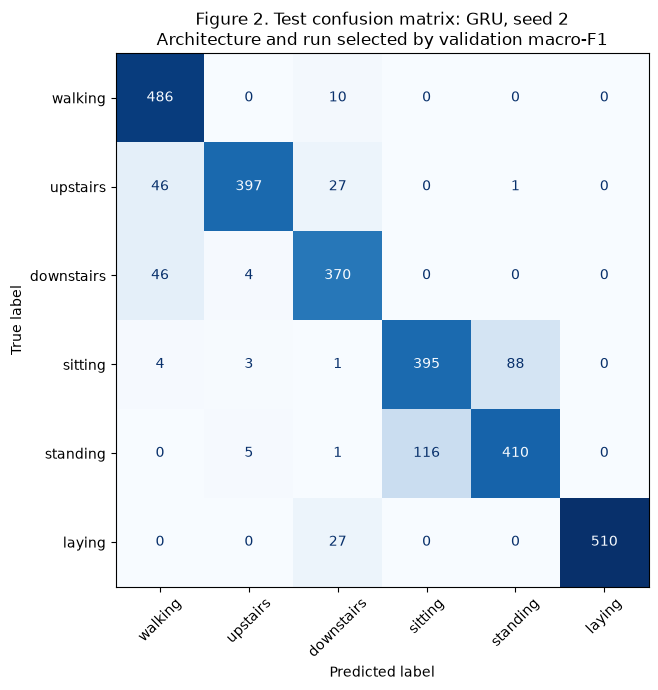

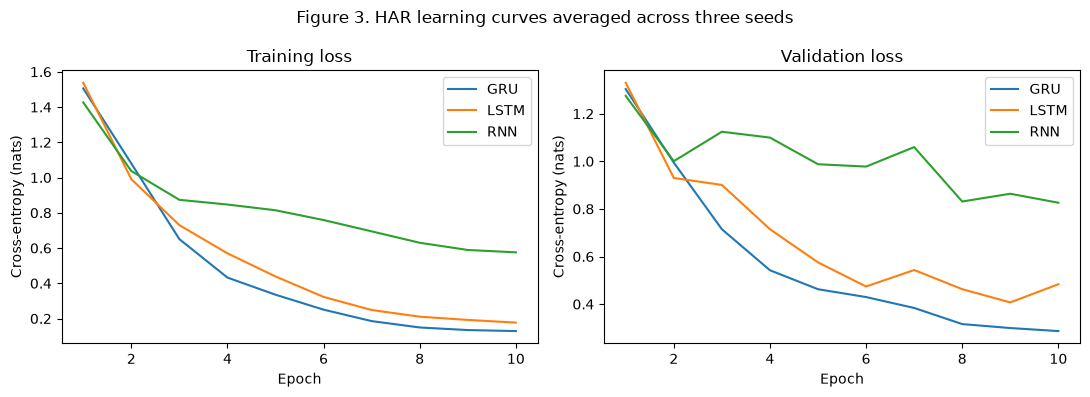

Selected architecture: GRU representative seed: 2 epoch: 9
Table 1 reports test metrics; Figure 2 shows the validation-selected model; Figure 3 shows learning curves.
Task 3 artifacts saved. Times are measured CPU/GPU times for the logged device, not assumed T4 times.


In [54]:
# Select architecture and representative run exclusively using validation F1.
best_kind = summary.validation_f1_mean.idxmax()
best_run = sorted([r for r in har_runs if r['model']==best_kind], key=lambda r: (-r['best_val_f1'], r['seed']))[0]
cm = confusion_matrix(y_test, best_run['predictions'], labels=list(range(6)))
assert cm.shape == (6,6) and cm.sum() == len(y_test)
assert abs(np.trace(cm)/cm.sum() - best_run['row']['test_acc']) < 1e-12
fig, ax = plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap='Blues')
ax.set_title(f'Figure 2. Test confusion matrix: {best_kind}, seed {best_run["seed"]}\nArchitecture and run selected by validation macro-F1')
fig.tight_layout()
fig.savefig(FIGURES / 'har_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
fig, axes = plt.subplots(1,2,figsize=(11,4))
for kind, group in history_table.groupby('model'):
    means = group.groupby('epoch')[['train_loss','val_loss']].mean()
    axes[0].plot(means.index, means.train_loss, label=kind)
    axes[1].plot(means.index, means.val_loss, label=kind)
for ax, title in zip(axes, ('Training loss', 'Validation loss')):
    ax.set(xlabel='Epoch', ylabel='Cross-entropy (nats)', title=title)
    ax.legend()
fig.suptitle('Figure 3. HAR learning curves averaged across three seeds')
fig.tight_layout()
fig.savefig(FIGURES / 'har_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Selected architecture:', best_kind, 'representative seed:', best_run['seed'], 'epoch:', best_run['best_epoch'])
print('Table 1 reports test metrics; Figure 2 shows the validation-selected model; Figure 3 shows learning curves.')
print('Task 3 artifacts saved. Times are measured CPU/GPU times for the logged device, not assumed T4 times.')

# Problem 1 — Task 4: Adding problem (10 marks)
Use all prescribed data: 10000/1000/1000 train/validation/test sequences with data seeds 0/1/2 at T=50/100/200/400. Model seeds 0/1/2 are separate. All architectures use h=64, batch 128, Adam 1e-3, 5 epochs, norm-1 gradient clipping and final-hidden-state linear regression. This short fixed CPU budget is chosen before examining test results; unsuccessful runs are valid evidence, not grounds for test-driven tuning. Checkpoints minimize validation MSE (earliest on ties). Solved means test MSE strictly below 0.05. The analytical constant-1 baseline is 1/6; measured test baselines are shown as well.

In [55]:
ADDING_CONFIG = dict(hidden_size=64, batch_size=128, epochs=5, lr=1e-3, clip_norm=1.0,
                     seeds=list(SEEDS), lengths=[50,100,200,400], threads=4,
                     device=str(HAR_DEVICE), torch_version=str(torch.__version__))
FORCE_ADDING_RERUN = False
ADDING_ID = experiment_fingerprint(ADDING_CONFIG,
    ('from pathlib import Path', 'def make_adding', 'class AddingRegressor', 'def evaluate_adding',
     'def run_adding(', 'def save_har_result', 'def experiment_fingerprint'))
ADDING_CACHE = DATA/'experiments'/'adding'/ADDING_ID
ADDING_CACHE.mkdir(parents=True,exist_ok=True)
print('Adding configuration:', ADDING_ID, ADDING_CONFIG)

Adding configuration: 7d60ee6ede81051e {'hidden_size': 64, 'batch_size': 128, 'epochs': 5, 'lr': 0.001, 'clip_norm': 1.0, 'seeds': [0, 1, 2], 'lengths': [50, 100, 200, 400], 'threads': 4, 'device': 'cpu', 'torch_version': '2.15.0+cpu'}


In [56]:
class AddingRegressor(nn.Module):
    def __init__(self, kind, hidden_size=64):
        super().__init__()
        self.recurrent = {'RNN':nn.RNN,'LSTM':nn.LSTM,'GRU':nn.GRU}[kind](2,hidden_size,batch_first=True)
        self.head = nn.Linear(hidden_size,1)

    def forward(self,x):
        _,state=self.recurrent(x)
        hidden=state[0] if isinstance(state,tuple) else state
        return self.head(hidden[-1]).squeeze(-1)

In [57]:
for kind,count in [('RNN',4417),('LSTM',17473),('GRU',13121)]:
    model=AddingRegressor(kind)
    output=model(torch.randn(4,50,2))
    assert output.shape==(4,)
    assert sum(p.numel() for p in model.parameters())==count
    output.square().mean().backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
print('PASS: adding-regressor shapes, counts and gradients')

PASS: adding-regressor shapes, counts and gradients


In [58]:
def evaluate_adding(model,loader):
    model.eval()
    predictions=[]
    targets=[]
    with torch.no_grad():
        for x,y in loader:
            predictions.append(model(x.to(HAR_DEVICE)).cpu())
            targets.append(y)
    pred=torch.cat(predictions)
    target=torch.cat(targets)
    return float((pred.double()-target.double()).square().mean()),pred.numpy()

In [59]:
class _AddingIdentity(nn.Module):
    def forward(self,x):return x[:,0]
fixture_loader=DataLoader(TensorDataset(torch.tensor([[1.],[2.],[3.]]),torch.tensor([0.,2.,1.])),batch_size=2)
fixture_mse,_=evaluate_adding(_AddingIdentity(),fixture_loader)
assert abs(fixture_mse-5/3)<1e-12
print('PASS: regression MSE is sample-weighted across incomplete batches')

PASS: regression MSE is sample-weighted across incomplete batches


In [60]:
def run_adding(kind,T,seed,*,config=None,cache_dir=None,run_id=None):
    config=ADDING_CONFIG if config is None else config
    cache_dir=ADDING_CACHE if cache_dir is None else cache_dir
    run_id=ADDING_ID if run_id is None else run_id
    cache_dir.mkdir(parents=True,exist_ok=True)
    cache=cache_dir/f'{kind}_{T}_{seed}.json'
    checkpoint=cache.with_suffix('.pt')
    notes=json.dumps(dict(task='adding',run_id=run_id,seq_len=T,**config),sort_keys=True)
    if cache.exists() and checkpoint.exists() and not FORCE_ADDING_RERUN:
        result=json.loads(cache.read_text())
        _,target=make_adding(1000,T,2)
        assert result['run_id']==run_id and len(result['history'])==config['epochs']
        assert len(result['predictions'])==1000
        np.testing.assert_allclose(np.mean((np.asarray(result['predictions'])-target)**2),result['row']['test_mse'],rtol=1e-10)
        save_har_result(result['row'],ROOT/'results.csv')
        print(f'CACHE {kind} T={T} seed={seed}: MSE={result["row"]["test_mse"]:.6f}')
        return result
    seed_everything(seed)
    generator=torch.Generator().manual_seed(seed)
    def loader(n,data_seed,shuffle=False):
        x,y=make_adding(n,T,data_seed)
        return DataLoader(TensorDataset(torch.from_numpy(x),torch.from_numpy(y)),
                          batch_size=config['batch_size'],shuffle=shuffle,
                          generator=generator if shuffle else None,num_workers=0)
    train=loader(10000,0,True)
    val=loader(1000,1)
    model=AddingRegressor(kind,config['hidden_size']).to(HAR_DEVICE)
    if 'effective_forget_bias' in config:
        assert kind=='LSTM'
        h=config['hidden_size']
        with torch.no_grad():
            model.recurrent.bias_ih_l0[h:2*h].fill_(config['effective_forget_bias'])
            model.recurrent.bias_hh_l0[h:2*h].zero_()
        assert torch.all(model.recurrent.bias_ih_l0[h:2*h]+model.recurrent.bias_hh_l0[h:2*h]==config['effective_forget_bias'])
    optimizer=torch.optim.Adam(model.parameters(),lr=config['lr'])
    history=[]
    best_mse=float('inf')
    best_state=None
    best_epoch=None
    for epoch in range(1,config['epochs']+1):
        model.train()
        if HAR_DEVICE.type=='cuda':torch.cuda.synchronize()
        start=time.perf_counter()
        loss_sum=0.
        for x,y in train:
            x,y=x.to(HAR_DEVICE),y.to(HAR_DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss=nn.functional.mse_loss(model(x),y)
            assert torch.isfinite(loss)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),config['clip_norm'],error_if_nonfinite=True)
            optimizer.step()
            loss_sum+=loss.item()*len(y)
        if HAR_DEVICE.type=='cuda':torch.cuda.synchronize()
        seconds=time.perf_counter()-start
        val_mse,_=evaluate_adding(model,val)
        history.append(dict(model=kind,seq_len=T,seed=seed,epoch=epoch,train_mse=loss_sum/10000,val_mse=val_mse,train_seconds=seconds))
        if val_mse<best_mse:
            best_mse,best_epoch=val_mse,epoch
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state)
    test_mse,pred=evaluate_adding(model,loader(1000,2))
    _,target=make_adding(1000,T,2)
    baseline=float(np.mean((target.astype(np.float64)-1)**2))
    row=dict.fromkeys(RESULT_COLUMNS)
    row.update(problem='P1',model=kind,seed=seed,seq_len=T,test_mse=test_mse,
               params=sum(p.numel() for p in model.parameters()),
               sec_per_epoch=float(np.mean([r['train_seconds'] for r in history])),notes=notes)
    result=dict(run_id=run_id,model=kind,seq_len=T,seed=seed,best_epoch=best_epoch,best_val_mse=best_mse,
                baseline_mse=baseline,history=history,predictions=pred.tolist(),row=row)
    torch.save({'state_dict':best_state,'config':config,'model':kind,'seq_len':T,'seed':seed,'best_epoch':best_epoch},checkpoint)
    temp=cache.with_suffix('.tmp');temp.write_text(json.dumps(result,indent=2));temp.replace(cache)
    save_har_result(row,ROOT/'results.csv')
    print(f'DONE {kind} T={T} seed={seed}: MSE={test_mse:.6f}; solved={test_mse<0.05}',flush=True)
    return result

In [61]:
adding_runs=[]

In [62]:
adding_runs.append(run_adding('RNN',50,0))

CACHE RNN T=50 seed=0: MSE=0.174024


In [63]:
adding_runs.append(run_adding('RNN',50,1))

CACHE RNN T=50 seed=1: MSE=0.174886


In [64]:
adding_runs.append(run_adding('RNN',50,2))

CACHE RNN T=50 seed=2: MSE=0.173998


In [65]:
adding_runs.append(run_adding('LSTM',50,0))

CACHE LSTM T=50 seed=0: MSE=0.174198


In [66]:
adding_runs.append(run_adding('LSTM',50,1))

CACHE LSTM T=50 seed=1: MSE=0.174690


In [67]:
adding_runs.append(run_adding('LSTM',50,2))

CACHE LSTM T=50 seed=2: MSE=0.174134


In [68]:
adding_runs.append(run_adding('GRU',50,0))

CACHE GRU T=50 seed=0: MSE=0.174579


In [69]:
adding_runs.append(run_adding('GRU',50,1))

CACHE GRU T=50 seed=1: MSE=0.170071


In [70]:
adding_runs.append(run_adding('GRU',50,2))

CACHE GRU T=50 seed=2: MSE=0.170452


In [71]:
adding_runs.append(run_adding('RNN',100,0))

CACHE RNN T=100 seed=0: MSE=0.169480


In [72]:
adding_runs.append(run_adding('RNN',100,1))

CACHE RNN T=100 seed=1: MSE=0.170536


In [73]:
adding_runs.append(run_adding('RNN',100,2))

CACHE RNN T=100 seed=2: MSE=0.169844


In [74]:
adding_runs.append(run_adding('LSTM',100,0))

CACHE LSTM T=100 seed=0: MSE=0.169520


In [75]:
adding_runs.append(run_adding('LSTM',100,1))

CACHE LSTM T=100 seed=1: MSE=0.169530


In [76]:
adding_runs.append(run_adding('LSTM',100,2))

CACHE LSTM T=100 seed=2: MSE=0.170857


In [77]:
adding_runs.append(run_adding('GRU',100,0))

CACHE GRU T=100 seed=0: MSE=0.170200


In [78]:
adding_runs.append(run_adding('GRU',100,1))

CACHE GRU T=100 seed=1: MSE=0.169039


In [79]:
adding_runs.append(run_adding('GRU',100,2))

CACHE GRU T=100 seed=2: MSE=0.168609


In [80]:
adding_runs.append(run_adding('RNN',200,0))

CACHE RNN T=200 seed=0: MSE=0.168458


In [81]:
adding_runs.append(run_adding('RNN',200,1))

CACHE RNN T=200 seed=1: MSE=0.167935


In [82]:
adding_runs.append(run_adding('RNN',200,2))

CACHE RNN T=200 seed=2: MSE=0.169451


In [83]:
adding_runs.append(run_adding('LSTM',200,0))

CACHE LSTM T=200 seed=0: MSE=0.167908


In [84]:
adding_runs.append(run_adding('LSTM',200,1))

CACHE LSTM T=200 seed=1: MSE=0.168865


In [85]:
adding_runs.append(run_adding('LSTM',200,2))

CACHE LSTM T=200 seed=2: MSE=0.168478


In [86]:
adding_runs.append(run_adding('GRU',200,0))

CACHE GRU T=200 seed=0: MSE=0.168903


In [87]:
adding_runs.append(run_adding('GRU',200,1))

CACHE GRU T=200 seed=1: MSE=0.168470


In [88]:
adding_runs.append(run_adding('GRU',200,2))

CACHE GRU T=200 seed=2: MSE=0.168265


In [89]:
adding_runs.append(run_adding('RNN',400,0))

CACHE RNN T=400 seed=0: MSE=0.154653


In [90]:
adding_runs.append(run_adding('RNN',400,1))

CACHE RNN T=400 seed=1: MSE=0.154188


In [91]:
adding_runs.append(run_adding('RNN',400,2))

CACHE RNN T=400 seed=2: MSE=0.154691


In [92]:
adding_runs.append(run_adding('LSTM',400,0))

CACHE LSTM T=400 seed=0: MSE=0.154115


In [93]:
adding_runs.append(run_adding('LSTM',400,1))

CACHE LSTM T=400 seed=1: MSE=0.154155


In [94]:
adding_runs.append(run_adding('LSTM',400,2))

CACHE LSTM T=400 seed=2: MSE=0.153199


In [95]:
adding_runs.append(run_adding('GRU',400,0))

CACHE GRU T=400 seed=0: MSE=0.153695


In [96]:
adding_runs.append(run_adding('GRU',400,1))

CACHE GRU T=400 seed=1: MSE=0.153606


In [97]:
adding_runs.append(run_adding('GRU',400,2))

CACHE GRU T=400 seed=2: MSE=0.153061


Table 2. Adding test MSE: mean/sample std and solved runs out of 3.


test_mse_mean  test_mse_std  solved  runs  baseline_mse
model seq_len                                                         
GRU   50            0.171701      0.002500       0     3      0.175392
      100           0.169283      0.000823       0     3      0.169709
      200           0.168546      0.000325       0     3      0.167942
      400           0.153454      0.000343       0     3      0.152720
LSTM  50            0.174341      0.000304       0     3      0.175392
      100           0.169969      0.000769       0     3      0.169709
      200           0.168417      0.000481       0     3      0.167942
      400           0.153823      0.000541       0     3      0.152720
RNN   50            0.174303      0.000505       0     3      0.175392
      100           0.169953      0.000536       0     3      0.169709
      200           0.168615      0.000770       0     3      0.167942
      400           0.154511      0.000280       0     3      0.152720

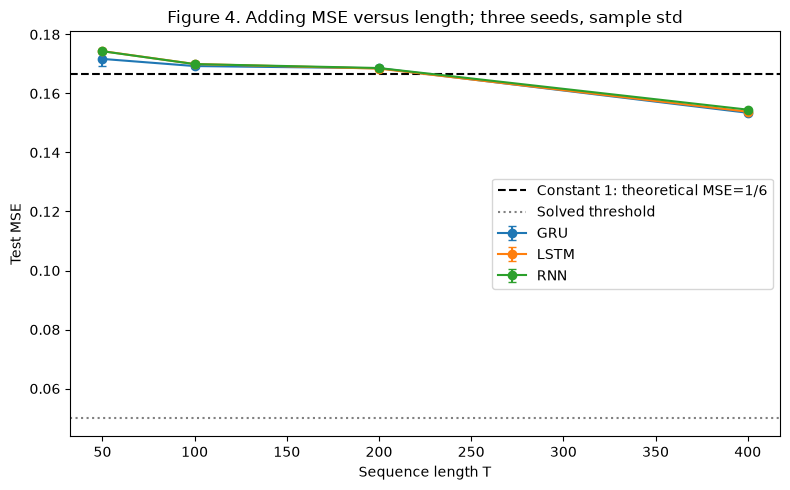

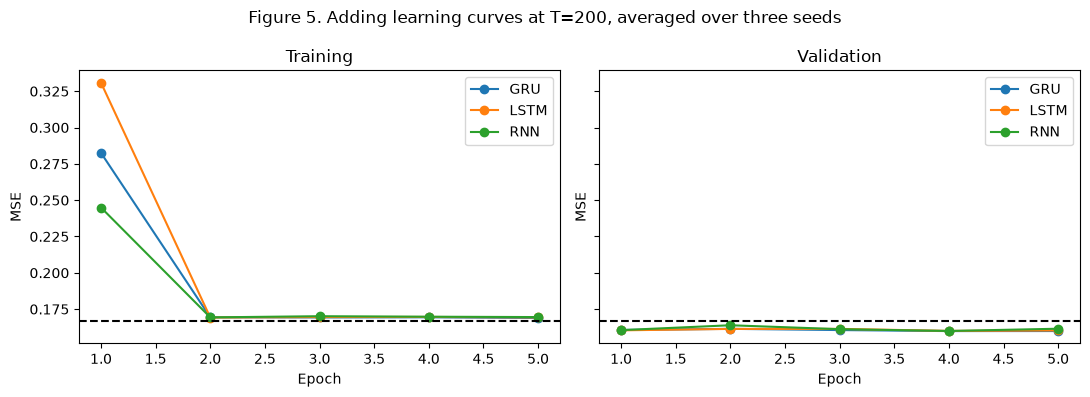

Table 2 and Figures 4–5 record this fixed five-epoch budget; unsolved runs are retained honestly.


In [98]:
assert len(adding_runs)==36
assert {(r['model'],r['seq_len'],r['seed']) for r in adding_runs}=={(m,T,s) for m in ('RNN','LSTM','GRU') for T in ADDING_CONFIG['lengths'] for s in SEEDS}
adding_table=pd.DataFrame([dict(model=r['model'],seq_len=r['seq_len'],seed=r['seed'],best_epoch=r['best_epoch'],
                              val_mse=r['best_val_mse'],test_mse=r['row']['test_mse'],baseline_mse=r['baseline_mse'],
                              params=r['row']['params'],sec_per_epoch=r['row']['sec_per_epoch'],solved=r['row']['test_mse']<0.05) for r in adding_runs])
adding_summary=adding_table.groupby(['model','seq_len']).agg(test_mse_mean=('test_mse','mean'),test_mse_std=('test_mse','std'),
    solved=('solved','sum'),runs=('seed','count'),baseline_mse=('baseline_mse','first'))
assert (adding_summary.runs==3).all() and not adding_summary.isna().any().any()
adding_history=pd.DataFrame([e for r in adding_runs for e in r['history']])
adding_predictions=pd.DataFrame([dict(model=r['model'],seq_len=r['seq_len'],seed=r['seed'],sample=i,predicted=p)
                                for r in adding_runs for i,p in enumerate(r['predictions'])])
adding_table.to_csv(METRICS/'adding_runs.csv',index=False)
adding_summary.to_csv(METRICS/'adding_summary.csv')
adding_history.to_csv(METRICS/'adding_history.csv',index=False)
adding_predictions.to_csv(METRICS/'adding_predictions.csv',index=False)
(METRICS/'adding_config.json').write_text(json.dumps(dict(run_id=ADDING_ID,**ADDING_CONFIG),indent=2))
print('Table 2. Adding test MSE: mean/sample std and solved runs out of 3.')
display(adding_summary)
fig,ax=plt.subplots(figsize=(8,5))
for kind,group in adding_summary.reset_index().groupby('model'):
    ax.errorbar(group.seq_len,group.test_mse_mean,yerr=group.test_mse_std,marker='o',capsize=3,label=kind)
ax.axhline(1/6,ls='--',color='black',label='Constant 1: theoretical MSE=1/6')
ax.axhline(0.05,ls=':',color='gray',label='Solved threshold')
ax.set(xlabel='Sequence length T',ylabel='Test MSE',title='Figure 4. Adding MSE versus length; three seeds, sample std')
ax.legend();fig.tight_layout();fig.savefig(FIGURES/'adding_mse_vs_length.png',dpi=150);plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)
for kind,g in adding_history[adding_history.seq_len==200].groupby('model'):
    stats=g.groupby('epoch')[['train_mse','val_mse']].mean()
    for ax,column in zip(axes,['train_mse','val_mse']):ax.plot(stats.index,stats[column],marker='o',label=kind)
for ax,title in zip(axes,['Training','Validation']):
    ax.axhline(1/6,ls='--',color='black');ax.set(xlabel='Epoch',ylabel='MSE',title=title);ax.legend()
fig.suptitle('Figure 5. Adding learning curves at T=200, averaged over three seeds')
fig.tight_layout();fig.savefig(FIGURES/'adding_curves_t200.png',dpi=150);plt.show()
print('Table 2 and Figures 4–5 record this fixed five-epoch budget; unsolved runs are retained honestly.')

# Problem 1 — Task 5: Gradients, ablations and analysis (15 marks)
AI-assisted under reported professor permission. Three chosen seeds 0/1/2. Gradient probes at T=100 use a fixed independent dataset seed 3, 32 examples, float64, and the same examples before/after training. Before means the exact seeded initialization of Task 4; after means its validation-selected checkpoint. Compare parameter gradients and predictions with the library model as a graph-correctness check. Plot the batch-mean L2 norm of dL/dh_t for mean MSE. LSTM h_t and c_t are separate graph nodes; dL/dh_t is the partial derivative at the hidden-state node, not the total derivative through cell memory. Gradient magnitude also depends on loss scale; do not infer memory solely from magnitude.

Sweep: LSTM/GRU h=16/32/64/128, three seeds each; reuse h=64 Task 3 runs, train remaining widths with the same 10-epoch HAR configuration and subject splits. Odd ID (3): LSTM T=200 effective forget bias 0 versus 1, three seeds and five epochs each. Only forget biases change in each paired comparison; set input forget bias to the requested value and recurrent forget bias to zero.

In [99]:
HAR_BASE = json.loads((METRICS/'har_config.json').read_text())
ADDING_BASE = json.loads((METRICS/'adding_config.json').read_text())
TASK5_CONFIG = dict(seeds=list(SEEDS),widths=[16,32,64,128],probe_T=100,probe_n=32,probe_seed=3,
                    har_base=HAR_BASE,adding_base=ADDING_BASE,forget_biases=[0,1])
_task5_nb=nbformat.read(ROOT/'problem1/problem1.ipynb',as_version=4)
_task5_start=next(i for i,c in enumerate(_task5_nb.cells) if c.source.startswith('# Problem 1 — Task 5:'))
_deps=[c.source for c in _task5_nb.cells if c.source.startswith(('def run_har(', 'def run_adding(', 'class HARClassifier','class AddingRegressor'))]
TASK5_ID=hashlib.sha256((json.dumps(TASK5_CONFIG,sort_keys=True)+'\n'.join(_deps+[c.source for c in _task5_nb.cells[_task5_start:]])).encode()).hexdigest()[:16]
_aliases=json.loads((METRICS/'cache_aliases.json').read_text()) if (METRICS/'cache_aliases.json').exists() else {}
TASK5_ID=_aliases.get(TASK5_ID,{}).get('run_id',TASK5_ID)
TASK5_CACHE=DATA/'experiments'/'task5'/TASK5_ID
TASK5_CACHE.mkdir(parents=True,exist_ok=True)
FORCE_HAR_RERUN=False
FORCE_ADDING_RERUN=False
print('Task 5:',TASK5_ID)

Task 5: cee2760cd83588bd


In [100]:
def hidden_gradient_probe(kind, seed, trained):
    seed_everything(seed)
    reference=AddingRegressor(kind).double()
    if trained:
        file=DATA/'experiments'/'adding'/ADDING_BASE['run_id']/f'{kind}_100_{seed}.pt'
        reference.load_state_dict(torch.load(file,weights_only=True)['state_dict'])
    cls={'RNN':MyRNNCell,'LSTM':MyLSTMCell,'GRU':MyGRUCell}[kind]
    cell=cls(2,64).double()
    copy_reference_weights(cell,reference.recurrent,kind,2,64)
    x,y=make_adding(32,100,3)
    x=torch.from_numpy(x).double();target=torch.from_numpy(y).double()
    h=torch.zeros(32,64,dtype=torch.float64,requires_grad=True)
    c=torch.zeros_like(h)
    nodes=[]
    for t in range(100):
        if kind=='LSTM':h,c=cell(x[:,t],(h,c))
        else:h=cell(x[:,t],h)
        h.retain_grad();nodes.append(h)
    pred=reference.head(h).squeeze(-1)
    expected=reference(x)
    torch.testing.assert_close(pred,expected,atol=1e-10,rtol=1e-9)
    loss=(pred-target).square().mean()
    loss.backward()
    # Compare parameter gradients to the fused reference's whole recurrent graph.
    reference.zero_grad(set_to_none=True)
    (reference(x)-target).square().mean().backward()
    for name,param in cell.named_parameters():
        torch.testing.assert_close(param.grad,getattr(reference.recurrent,name+'_l0').grad,atol=1e-10,rtol=1e-8)
    norms=[float(node.grad.norm(dim=1).mean()) for node in nodes]
    assert len(norms)==100 and np.isfinite(norms).all() and np.all(np.asarray(norms)>=0)
    assert norms[-1]>0
    return [dict(model=kind,seed=seed,phase='after' if trained else 'before',t=t+1,
                 norm=value,probe_loss=float(loss.detach())) for t,value in enumerate(norms)]

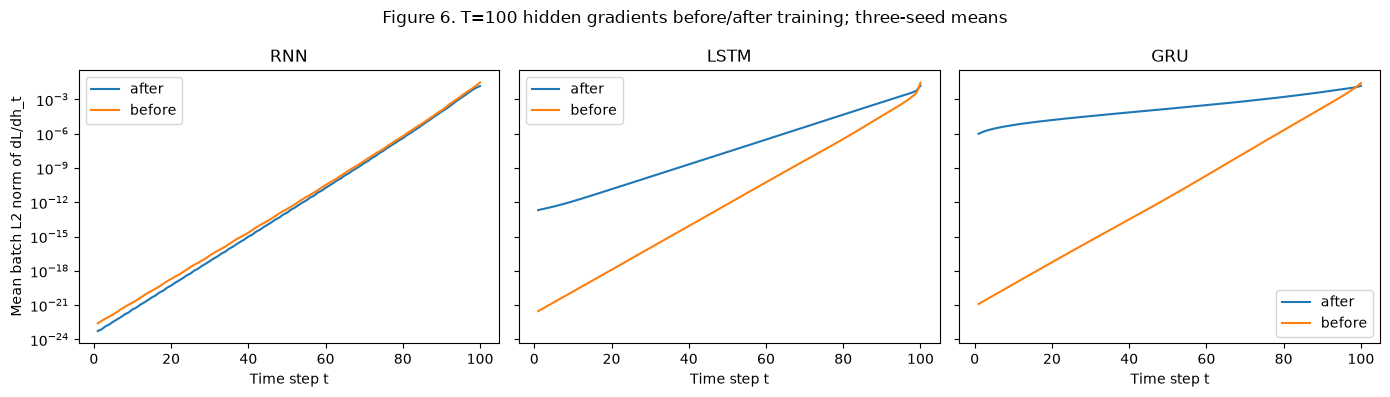

PASS: 18 graph probes; outputs and parameter gradients agree with library models


In [101]:
gradient_records=[]
for kind in ('RNN','LSTM','GRU'):
    for seed in SEEDS:
        for trained in (False,True):gradient_records.extend(hidden_gradient_probe(kind,seed,trained))
gradient_table=pd.DataFrame(gradient_records)
assert len(gradient_table)==1800
assert gradient_table.groupby(['model','seed','phase']).size().eq(100).all()
gradient_table.to_csv(METRICS/'hidden_gradients.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,kind in zip(axes,('RNN','LSTM','GRU')):
    for phase,group in gradient_table[gradient_table.model==kind].groupby('phase'):
        values=group.groupby('t').norm.mean()
        ax.semilogy(values.index,np.maximum(values,1e-300),label=phase)
    ax.set(xlabel='Time step t',title=kind);ax.legend()
axes[0].set_ylabel('Mean batch L2 norm of dL/dh_t')
fig.suptitle('Figure 6. T=100 hidden gradients before/after training; three-seed means')
fig.tight_layout();fig.savefig(FIGURES/'hidden_gradient_norms.png',dpi=150);plt.show()
print('PASS: 18 graph probes; outputs and parameter gradients agree with library models')

In [102]:
def sweep_har(kind,width,seed):
    if width==64:
        file=DATA/'experiments'/'har'/HAR_BASE['run_id']/f'{kind}_{seed}.json'
        result=json.loads(file.read_text())
        assert result['row']['params']==sum(p.numel() for p in HARClassifier(kind,64).parameters())
        print(f'REUSE HAR {kind} h=64 seed={seed}')
    else:
        config={k:v for k,v in HAR_BASE.items() if k!='run_id'}
        config['hidden_size']=width
        result=run_har(kind,seed,config=config,cache_dir=TASK5_CACHE/'har'/f'h{width}',run_id=TASK5_ID)
    return {**result,'hidden_size':width}

In [103]:
sweep_runs=[]

In [104]:
sweep_runs.append(sweep_har('LSTM',16,0))

CACHE LSTM seed 0: accuracy=0.8242


In [105]:
sweep_runs.append(sweep_har('LSTM',16,1))

CACHE LSTM seed 1: accuracy=0.6943


In [106]:
sweep_runs.append(sweep_har('LSTM',16,2))

CACHE LSTM seed 2: accuracy=0.7479


In [107]:
sweep_runs.append(sweep_har('GRU',16,0))

CACHE GRU seed 0: accuracy=0.8073


In [108]:
sweep_runs.append(sweep_har('GRU',16,1))

CACHE GRU seed 1: accuracy=0.7628


In [109]:
sweep_runs.append(sweep_har('GRU',16,2))

CACHE GRU seed 2: accuracy=0.7869


In [110]:
sweep_runs.append(sweep_har('LSTM',32,0))

CACHE LSTM seed 0: accuracy=0.8422


In [111]:
sweep_runs.append(sweep_har('LSTM',32,1))

CACHE LSTM seed 1: accuracy=0.8609


In [112]:
sweep_runs.append(sweep_har('LSTM',32,2))

CACHE LSTM seed 2: accuracy=0.8409


In [113]:
sweep_runs.append(sweep_har('GRU',32,0))

CACHE GRU seed 0: accuracy=0.8812


In [114]:
sweep_runs.append(sweep_har('GRU',32,1))

CACHE GRU seed 1: accuracy=0.8744


In [115]:
sweep_runs.append(sweep_har('GRU',32,2))

CACHE GRU seed 2: accuracy=0.8666


In [116]:
sweep_runs.append(sweep_har('LSTM',64,0))

REUSE HAR LSTM h=64 seed=0


In [117]:
sweep_runs.append(sweep_har('LSTM',64,1))

REUSE HAR LSTM h=64 seed=1


In [118]:
sweep_runs.append(sweep_har('LSTM',64,2))

REUSE HAR LSTM h=64 seed=2


In [119]:
sweep_runs.append(sweep_har('GRU',64,0))

REUSE HAR GRU h=64 seed=0


In [120]:
sweep_runs.append(sweep_har('GRU',64,1))

REUSE HAR GRU h=64 seed=1


In [121]:
sweep_runs.append(sweep_har('GRU',64,2))

REUSE HAR GRU h=64 seed=2


In [122]:
sweep_runs.append(sweep_har('LSTM',128,0))

CACHE LSTM seed 0: accuracy=0.8856


In [123]:
sweep_runs.append(sweep_har('LSTM',128,1))

CACHE LSTM seed 1: accuracy=0.8850


In [124]:
sweep_runs.append(sweep_har('LSTM',128,2))

CACHE LSTM seed 2: accuracy=0.8778


In [125]:
sweep_runs.append(sweep_har('GRU',128,0))

CACHE GRU seed 0: accuracy=0.8972


In [126]:
sweep_runs.append(sweep_har('GRU',128,1))

CACHE GRU seed 1: accuracy=0.8907


In [127]:
sweep_runs.append(sweep_har('GRU',128,2))

CACHE GRU seed 2: accuracy=0.8833


Table 3. HAR hidden-size sweep over three seeds (sample std).


accuracy_mean  accuracy_std   f1_mean    f1_std  params  \
model hidden_size                                                            
GRU   16                0.785658      0.022252  0.776123  0.021856    1398   
      32                0.874109      0.007301  0.874079  0.006394    4326   
      64                0.881914      0.010354  0.881923  0.010410   14790   
      128               0.890397      0.006962  0.889096  0.009171   54150   
LSTM  16                0.755458      0.065312  0.743419  0.075456    1830   
      32                0.847981      0.011188  0.846699  0.011212    5702   
      64                0.877050      0.002926  0.876755  0.002340   19590   
      128               0.882819      0.004323  0.883307  0.003761   71942   

                   sec_per_epoch  
model hidden_size                 
GRU   16                1.121742  
      32                1.590735  
      64                2.279295  
      128               4.181357  
LSTM  16                0.298132  
      32                0.537980  
      64                1.181613  
      128               2.997344

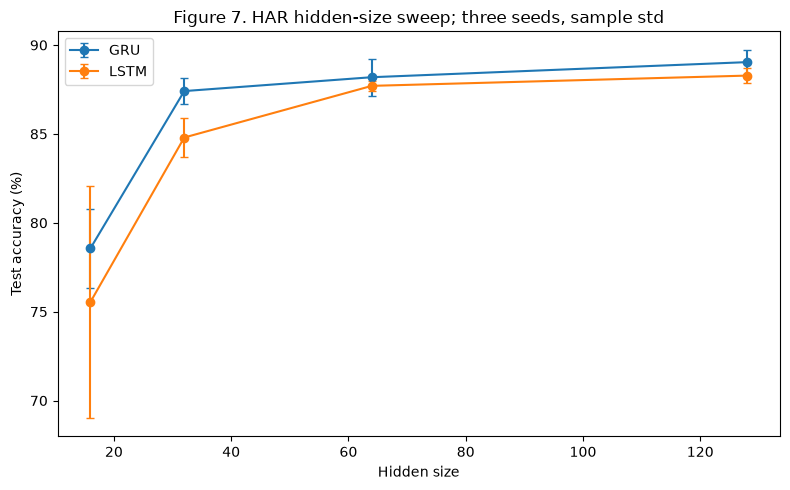

In [128]:
assert len(sweep_runs)==24
sweep_table=pd.DataFrame([dict(model=r['model'],hidden_size=r['hidden_size'],seed=r['seed'],
    test_acc=r['row']['test_acc'],macro_f1=r['row']['macro_f1'],params=r['row']['params'],sec_per_epoch=r['row']['sec_per_epoch'],
    val_macro_f1=r['best_val_f1'],best_epoch=r['best_epoch']) for r in sweep_runs])
sweep_summary=sweep_table.groupby(['model','hidden_size']).agg(accuracy_mean=('test_acc','mean'),accuracy_std=('test_acc','std'),
    f1_mean=('macro_f1','mean'),f1_std=('macro_f1','std'),params=('params','first'),sec_per_epoch=('sec_per_epoch','mean'))
assert not sweep_summary.isna().any().any()
sweep_table.to_csv(METRICS/'har_hidden_sweep_runs.csv',index=False)
sweep_summary.to_csv(METRICS/'har_hidden_sweep_summary.csv')
pd.DataFrame([dict(hidden_size=r['hidden_size'],**e) for r in sweep_runs for e in r['history']]).to_csv(METRICS/'har_hidden_sweep_history.csv',index=False)
pd.DataFrame([dict(hidden_size=r['hidden_size'],model=r['model'],seed=r['seed'],sample=i,predicted=p)
              for r in sweep_runs for i,p in enumerate(r['predictions'])]).to_csv(METRICS/'har_hidden_sweep_predictions.csv',index=False)
print('Table 3. HAR hidden-size sweep over three seeds (sample std).');display(sweep_summary)
fig,ax=plt.subplots(figsize=(8,5))
for kind,g in sweep_summary.reset_index().groupby('model'):
    ax.errorbar(g.hidden_size,g.accuracy_mean*100,yerr=g.accuracy_std*100,marker='o',capsize=3,label=kind)
ax.set(xlabel='Hidden size',ylabel='Test accuracy (%)',title='Figure 7. HAR hidden-size sweep; three seeds, sample std');ax.legend()
fig.tight_layout();fig.savefig(FIGURES/'har_hidden_sweep.png',dpi=150);plt.show()

In [129]:
def run_forget_ablation(bias,seed):
    config={k:v for k,v in ADDING_BASE.items() if k!='run_id'}
    config['effective_forget_bias']=bias
    result=run_adding('LSTM',200,seed,config=config,cache_dir=TASK5_CACHE/'forget'/f'bias{bias}',run_id=TASK5_ID)
    checkpoint=torch.load(TASK5_CACHE/'forget'/f'bias{bias}'/f'LSTM_200_{seed}.pt',weights_only=True)
    assert checkpoint['config']['effective_forget_bias']==bias
    return dict(forget_bias=bias,**result)

In [130]:
forget_runs=[]

In [131]:
forget_runs.append(run_forget_ablation(0,0))

CACHE LSTM T=200 seed=0: MSE=0.167918


In [132]:
forget_runs.append(run_forget_ablation(0,1))

CACHE LSTM T=200 seed=1: MSE=0.168808


In [133]:
forget_runs.append(run_forget_ablation(0,2))

CACHE LSTM T=200 seed=2: MSE=0.168476


In [134]:
forget_runs.append(run_forget_ablation(1,0))

CACHE LSTM T=200 seed=0: MSE=0.168328


In [135]:
forget_runs.append(run_forget_ablation(1,1))

CACHE LSTM T=200 seed=1: MSE=0.168940


In [136]:
forget_runs.append(run_forget_ablation(1,2))

CACHE LSTM T=200 seed=2: MSE=0.168216


Table 4. T=200 effective forget-bias ablation, three seeds.


,test_mse_mean,test_mse_std,solved
forget_bias,,,
0,0.168401,0.000449,0
1,0.168494,0.000390,0


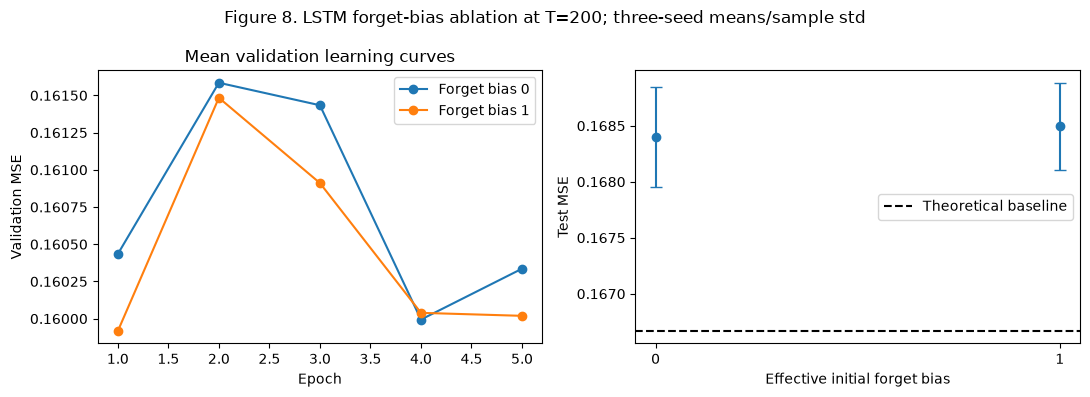

Task 5 experiments completed; interpretation follows in the evidence-based analysis.


In [137]:
assert len(forget_runs)==6
forget_table=pd.DataFrame([dict(forget_bias=r['forget_bias'],seed=r['seed'],best_epoch=r['best_epoch'],
    test_mse=r['row']['test_mse'],val_mse=r['best_val_mse'],solved=r['row']['test_mse']<0.05) for r in forget_runs])
forget_summary=forget_table.groupby('forget_bias').agg(test_mse_mean=('test_mse','mean'),test_mse_std=('test_mse','std'),solved=('solved','sum'))
forget_history=pd.DataFrame([dict(forget_bias=r['forget_bias'],**e) for r in forget_runs for e in r['history']])
forget_table.to_csv(METRICS/'forget_bias_runs.csv',index=False);forget_summary.to_csv(METRICS/'forget_bias_summary.csv')
forget_history.to_csv(METRICS/'forget_bias_history.csv',index=False)
pd.DataFrame([dict(forget_bias=r['forget_bias'],seed=r['seed'],sample=i,predicted=p) for r in forget_runs for i,p in enumerate(r['predictions'])]).to_csv(METRICS/'forget_bias_predictions.csv',index=False)
(METRICS/'task5_config.json').write_text(json.dumps(dict(run_id=TASK5_ID,**TASK5_CONFIG),indent=2))
print('Table 4. T=200 effective forget-bias ablation, three seeds.');display(forget_summary)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for bias,g in forget_history.groupby('forget_bias'):
    v=g.groupby('epoch')[['train_mse','val_mse']].mean()
    axes[0].plot(v.index,v.val_mse,marker='o',label=f'Forget bias {bias}')
axes[0].set(xlabel='Epoch',ylabel='Validation MSE',title='Mean validation learning curves');axes[0].legend()
axes[1].errorbar(forget_summary.index,forget_summary.test_mse_mean,yerr=forget_summary.test_mse_std,fmt='o',capsize=4)
axes[1].axhline(1/6,ls='--',color='black',label='Theoretical baseline');axes[1].set(xticks=[0,1],xlabel='Effective initial forget bias',ylabel='Test MSE');axes[1].legend()
fig.suptitle('Figure 8. LSTM forget-bias ablation at T=200; three-seed means/sample std')
fig.tight_layout();fig.savefig(FIGURES/'forget_bias_ablation.png',dpi=150);plt.show()
print('Task 5 experiments completed; interpretation follows in the evidence-based analysis.')